# 📈 Drift Method for Time Series Forecasting

A practical, end-to-end walkthrough of the **Drift Method** using Python.

## What you will learn
- Understand the intuition and mathematical formulation of the Drift Method.
- Build a multi-step Drift forecast from a univariate time series.
- Understand the relationship between Drift and Naive forecasting.
- Evaluate the forecast using a chronological train/test split.
- Compare Drift with Naive and Average forecasting baselines.
- Inspect forecast errors, visualize results, and understand limitations.

> **Important:** The Drift Method is a simple benchmark. It extrapolates the average historical change into the future; it does not learn complex patterns or seasonality.

## 1. Introduction

The **Drift Method** is a baseline forecasting technique that extends the Naive Method by allowing the forecast to move up or down over time.

- **Naive Method:** assumes the future will remain at the last observed value.
- **Drift Method:** assumes the average change between the first and last observations will continue into the future.

For example, if demand increases from 100 units to 160 units over 12 monthly observations, the average change per month is:

$$
\mathrm{Drift} = \frac{160 - 100}{12 - 1} \approx 5.45
$$

The method adds approximately 5.45 units for every future month.

### When can it be useful?
- A time series has a reasonably consistent upward or downward direction.
- You need a simple trend-aware benchmark.
- You want to compare more advanced forecasting models against a transparent baseline.

### When is it not a good fit?
- Strong seasonality is present.
- The series has abrupt structural changes.
- The historical average change is not representative of the future.
- Demand is intermittent or dominated by irregular spikes.

## 2. Mathematical formulation

Let:

- $ y_t $ = observed value at time $ t $
- $ T $ = index of the last observation in the training data
- $ h $ = forecast horizon (number of steps ahead)
- $ y_1 $ = first training observation
- $ y_T $ = last training observation

The estimated drift per time step is:

$$
d = \frac{y_T-y_1}{T-1}
$$

The forecast $ h $ steps ahead is:

$$
\boxed{\hat{y}_{T+h}=y_T+h\left(\frac{y_T-y_1}{T-1}\right)}
$$

### Intuition
1. Calculate the total change from the first to the last training observation.
2. Divide by the number of intervals between them.
3. Treat that value as the average change per period.
4. Add the estimated change repeatedly to the last observed value.

The denominator is $ T-1 $, not $ T $, because $ T $ observations contain $ T-1 $ intervals.

## 3. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

## 4. Create a sample time series

We will create synthetic monthly demand with:
- a starting demand level,
- a gradual upward trend,
- random noise.

We intentionally keep strong seasonality out of this example so that the trend extrapolation is easier to inspect. The data is synthetic and is only intended for learning.

In [2]:
np.random.seed(42)

periods = 72
dates = pd.date_range(start="2020-01-01", periods=periods, freq="MS")

base_level = 100
true_monthly_trend = 2.0
noise = np.random.normal(loc=0, scale=8, size=periods)

demand = base_level + true_monthly_trend * np.arange(periods) + noise

ts = pd.Series(demand, index=dates, name="Demand")

display(ts.head())
display(ts.tail())

2020-01-01    103.973713
2020-02-01    100.893886
2020-03-01    109.181508
2020-04-01    118.184239
2020-05-01    106.126773
Freq: MS, Name: Demand, dtype: float64

2025-08-01    242.028263
2025-09-01    238.893088
2025-10-01    232.839042
2025-11-01    242.891165
2025-12-01    254.304293
Freq: MS, Name: Demand, dtype: float64

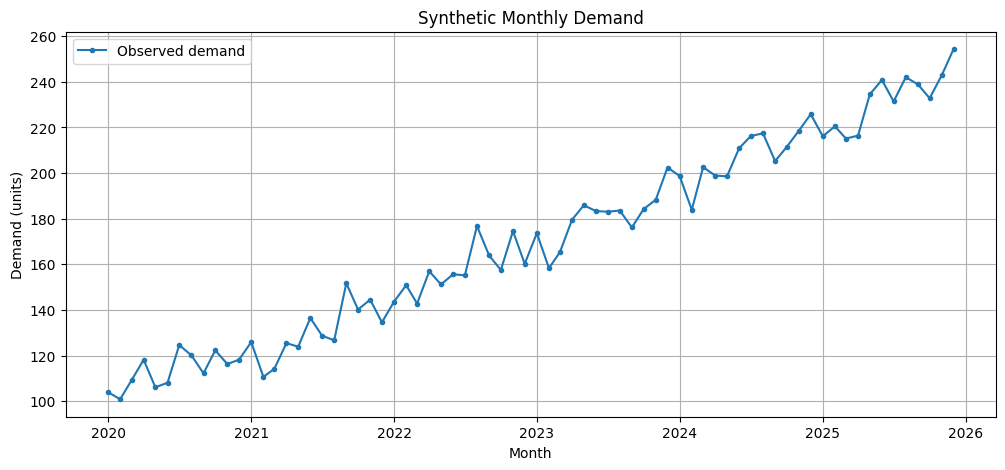

In [3]:
plt.figure()
plt.plot(ts.index, ts.values, marker="o", markersize=3, label="Observed demand")
plt.title("Synthetic Monthly Demand")
plt.xlabel("Month")
plt.ylabel("Demand (units)")
plt.legend()
plt.show()

## 5. Train/test split

For time series forecasting, preserve chronological order:
- Earlier observations are used for training.
- Later observations are held out for testing.

We use the first 60 months for training and the final 12 months for testing. The test observations must not be used to calculate the drift.

In [4]:
test_size = 12
train = ts.iloc[:-test_size]
test = ts.iloc[-test_size:]

print(f"Training observations: {len(train)}")
print(f"Testing observations:  {len(test)}")
print(f"Training period: {train.index.min().date()} to {train.index.max().date()}")
print(f"Testing period:  {test.index.min().date()} to {test.index.max().date()}")

Training observations: 60
Testing observations:  12
Training period: 2020-01-01 to 2024-12-01
Testing period:  2025-01-01 to 2025-12-01


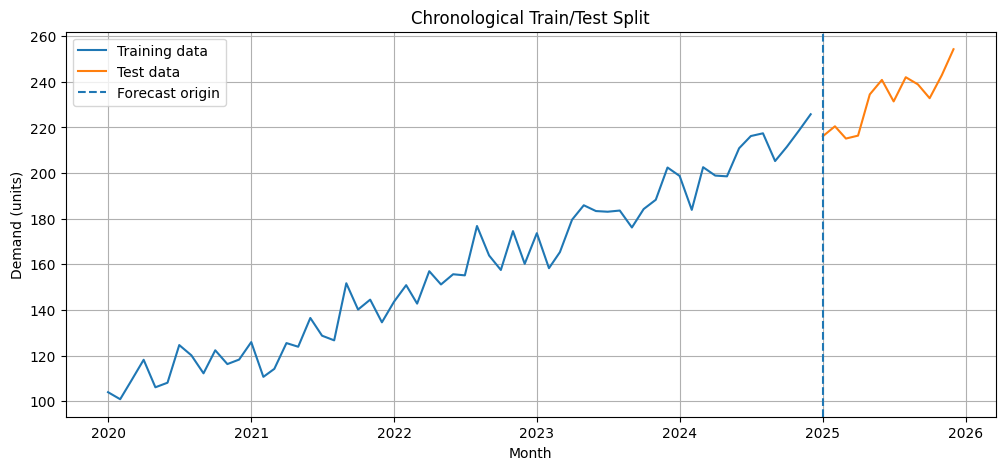

In [5]:
plt.figure()
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Test data")
plt.axvline(test.index[0], linestyle="--", label="Forecast origin")
plt.title("Chronological Train/Test Split")
plt.xlabel("Month")
plt.ylabel("Demand (units)")
plt.legend()
plt.show()

## 6. Calculate the drift

The drift is the average change per time interval between the first and last training observations:

$$
d = \frac{y_T-y_1}{T-1}
$$

Let's calculate it from the training data only.

In [6]:
first_value = train.iloc[0]
last_value = train.iloc[-1]
n_train = len(train)

drift_per_period = (last_value - first_value) / (n_train - 1)

print(f"First training value: {first_value:.2f}")
print(f"Last training value:  {last_value:.2f}")
print(f"Number of intervals:  {n_train - 1}")
print(f"Estimated drift:      {drift_per_period:.4f} units per month")

First training value: 103.97
Last training value:  225.80
Number of intervals:  59
Estimated drift:      2.0649 units per month


## 7. Build the Drift forecasting function

The function below:
- accepts a training series,
- calculates the average change per time step,
- projects that change across the requested horizon,
- returns one forecast for each future step.

It uses only the supplied training data.

In [7]:
def drift_forecast(train_series, horizon):
    """Generate a multi-step Drift forecast.

    Parameters
    ----------
    train_series : pandas Series or array-like
        Historical observations in chronological order.
    horizon : int
        Number of future time steps to forecast.

    Returns
    -------
    numpy.ndarray
        Forecast values from step 1 through `horizon`.
    """
    values = np.asarray(train_series, dtype=float)

    if values.ndim != 1:
        raise ValueError("train_series must be one-dimensional.")
    if len(values) < 2:
        raise ValueError("At least two observations are required.")
    if horizon < 1:
        raise ValueError("horizon must be at least 1.")

    drift = (values[-1] - values[0]) / (len(values) - 1)
    steps = np.arange(1, horizon + 1)

    return values[-1] + steps * drift


drift_predictions = drift_forecast(train, horizon=len(test))

forecast = pd.Series(
    drift_predictions,
    index=test.index,
    name="Drift Forecast"
)

display(forecast.to_frame())

,Drift Forecast
2025-01-01,227.869287
2025-02-01,229.934213
2025-03-01,231.999140
2025-04-01,234.064066
2025-05-01,236.128992
2025-06-01,238.193918
2025-07-01,240.258845
2025-08-01,242.323771
2025-09-01,244.388697
2025-10-01,246.453623


## 8. Visualize the Drift forecast

The forecast begins at the final training observation and continues with a constant average change per period.

A straight forecast line does **not** mean actual demand will follow a perfectly straight path. It is the model's extrapolation of the historical average change.

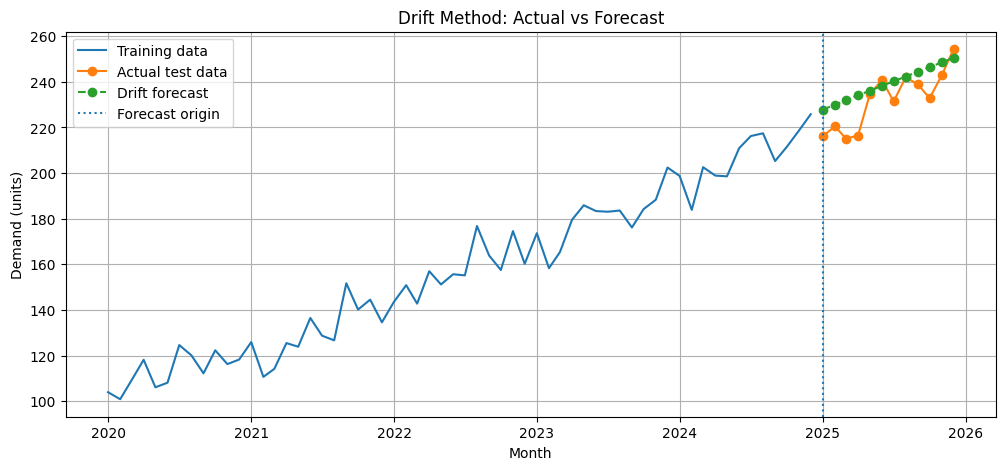

In [8]:
plt.figure()
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, marker="o", label="Actual test data")
plt.plot(forecast.index, forecast, marker="o", linestyle="--", label="Drift forecast")
plt.axvline(test.index[0], linestyle=":", label="Forecast origin")
plt.title("Drift Method: Actual vs Forecast")
plt.xlabel("Month")
plt.ylabel("Demand (units)")
plt.legend()
plt.show()

## 9. Compare Drift with Naive and Average methods

It is useful to compare a model with simple baselines.

### Naive forecast
Repeats the last training observation for every future period:

$$
\hat{y}_{T+h}=y_T
$$

### Average forecast
Repeats the mean of the training observations:

$$
\hat{y}_{T+h}=\bar{y}
$$

### Drift forecast
Extends the average change from the first to the last training observation:

$$
\hat{y}_{T+h}=y_T+h\frac{y_T-y_1}{T-1}
$$

All three forecasts below use only the training set.

In [9]:
naive_predictions = np.repeat(train.iloc[-1], len(test))
average_predictions = np.repeat(train.mean(), len(test))

predictions = pd.DataFrame({
    "Actual": test,
    "Naive": naive_predictions,
    "Average": average_predictions,
    "Drift": drift_predictions
}, index=test.index)

display(predictions.round(2))

,Actual,Naive,Average,Drift
2025-01-01,216.17,225.8,157.76,227.87
2025-02-01,220.51,225.8,157.76,229.93
2025-03-01,215.15,225.8,157.76,232.00
2025-04-01,216.43,225.8,157.76,234.06
2025-05-01,234.50,225.8,157.76,236.13
2025-06-01,240.85,225.8,157.76,238.19
2025-07-01,231.42,225.8,157.76,240.26
2025-08-01,242.03,225.8,157.76,242.32
2025-09-01,238.89,225.8,157.76,244.39
2025-10-01,232.84,225.8,157.76,246.45


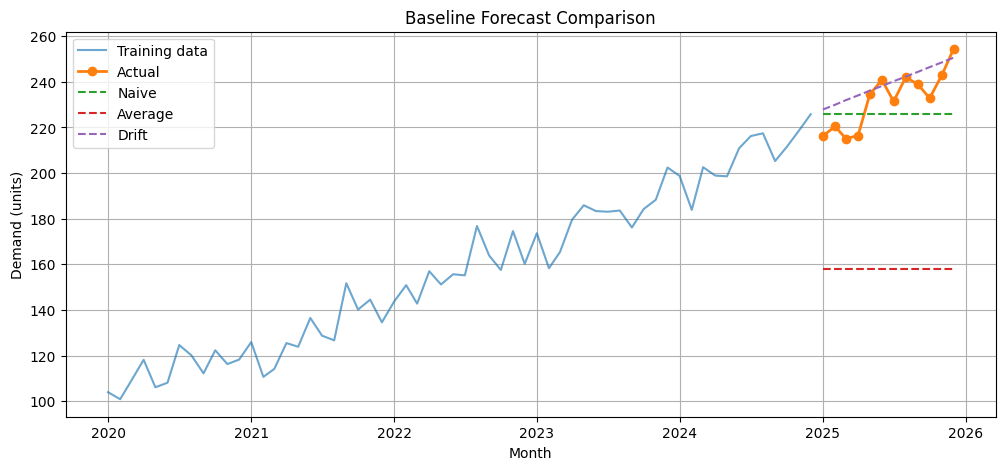

In [10]:
plt.figure()
plt.plot(train.index, train, label="Training data", alpha=0.65)
plt.plot(test.index, test, marker="o", linewidth=2, label="Actual")
plt.plot(test.index, naive_predictions, linestyle="--", label="Naive")
plt.plot(test.index, average_predictions, linestyle="--", label="Average")
plt.plot(test.index, drift_predictions, linestyle="--", label="Drift")
plt.title("Baseline Forecast Comparison")
plt.xlabel("Month")
plt.ylabel("Demand (units)")
plt.legend()
plt.show()

## 10. Evaluate forecast accuracy

We will use four common metrics:

- **MAE:** average absolute forecast error; lower is better.
- **RMSE:** penalizes larger errors more strongly; lower is better.
- **MAPE:** average absolute percentage error; undefined when actual values are zero.
- **WMAPE:** total absolute error divided by total absolute actual demand; useful for aggregating error across observations.

$$
MAE=\frac{1}{n}\sum_{t=1}^{n}|y_t-\hat{y}_t|
$$

$$
RMSE=\sqrt{\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat{y}_t)^2}
$$

$$
MAPE=\frac{100}{n}\sum_{t=1}^{n}\left|\frac{y_t-\hat{y}_t}{y_t}\right|
$$

$$
WMAPE=100\times\frac{\sum_{t=1}^{n}|y_t-\hat{y}_t|}{\sum_{t=1}^{n}|y_t|}
$$

For MAPE, we exclude zero actual values. If all actual values are zero, MAPE is reported as NaN.

In [11]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    nonzero_mask = actual != 0
    if nonzero_mask.any():
        mape = np.mean(
            np.abs((actual[nonzero_mask] - predicted[nonzero_mask]) /
                   actual[nonzero_mask])
        ) * 100
    else:
        mape = np.nan

    denominator = np.sum(np.abs(actual))
    wmape = (
        np.sum(np.abs(actual - predicted)) / denominator * 100
        if denominator != 0 else np.nan
    )

    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape, "WMAPE (%)": wmape}


metric_rows = []
for model_name in ["Naive", "Average", "Drift"]:
    metric_rows.append({
        "Model": model_name,
        **calculate_metrics(test, predictions[model_name])
    })

metrics = pd.DataFrame(metric_rows).set_index("Model")
display(metrics.round(3))

,MAE,RMSE,MAPE (%),WMAPE (%)
Model,,,,
Naive,12.188,13.675,5.164,5.250
Average,74.403,75.381,31.861,32.047
Drift,8.123,9.872,3.611,3.499


### Interpreting the results

- Lower MAE and RMSE indicate smaller errors in the original demand units.
- Lower MAPE and WMAPE indicate smaller percentage errors.
- The best model can differ by metric.
- A model that performs best on this one synthetic test period is not automatically best for another series or future period.

Do not select a forecasting method based only on how closely it follows the training data. Evaluate it on data that was not used to fit the forecast.

## 11. Inspect forecast errors

Forecast error is:

$$
e_t = y_t-\hat{y}_t
$$

- Positive error: actual demand was higher than forecast (under-forecast).
- Negative error: actual demand was lower than forecast (over-forecast).

Inspecting errors can reveal persistent over- or under-forecasting.

In [12]:
error_analysis = pd.DataFrame({
    "Actual": test,
    "Forecast": forecast,
    "Error (Actual - Forecast)": test - forecast
})
display(error_analysis.round(2))

,Actual,Forecast,Error (Actual - Forecast)
2025-01-01,216.17,227.87,-11.70
2025-02-01,220.51,229.93,-9.42
2025-03-01,215.15,232.00,-16.85
2025-04-01,216.43,234.06,-17.63
2025-05-01,234.50,236.13,-1.63
2025-06-01,240.85,238.19,2.66
2025-07-01,231.42,240.26,-8.83
2025-08-01,242.03,242.32,-0.30
2025-09-01,238.89,244.39,-5.50
2025-10-01,232.84,246.45,-13.61


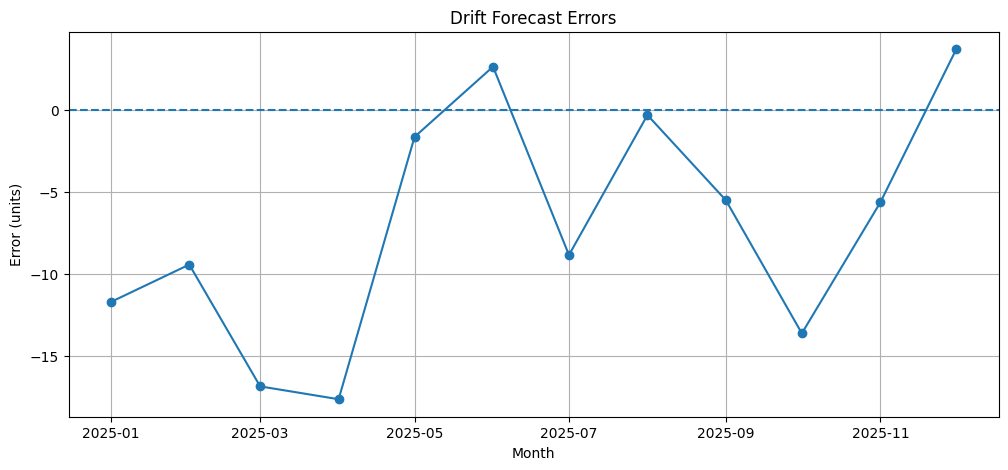

In [13]:
plt.figure()
plt.axhline(0, linestyle="--")
plt.plot(error_analysis.index, error_analysis["Error (Actual - Forecast)"],
         marker="o")
plt.title("Drift Forecast Errors")
plt.xlabel("Month")
plt.ylabel("Error (units)")
plt.show()

## 12. Forecast a future horizon

After evaluating the method, you can refit it using all currently available observations and forecast beyond the end of the series.

This example forecasts the next six months using the complete synthetic series.

In [14]:
future_horizon = 6
future_values = drift_forecast(ts, horizon=future_horizon)
future_dates = pd.date_range(
    start=ts.index[-1] + pd.offsets.MonthBegin(1),
    periods=future_horizon,
    freq="MS"
)
future_forecast = pd.Series(future_values, index=future_dates, name="Forecast")

display(future_forecast.to_frame().round(2))

,Forecast
2026-01-01,256.42
2026-02-01,258.54
2026-03-01,260.66
2026-04-01,262.77
2026-05-01,264.89
2026-06-01,267.01


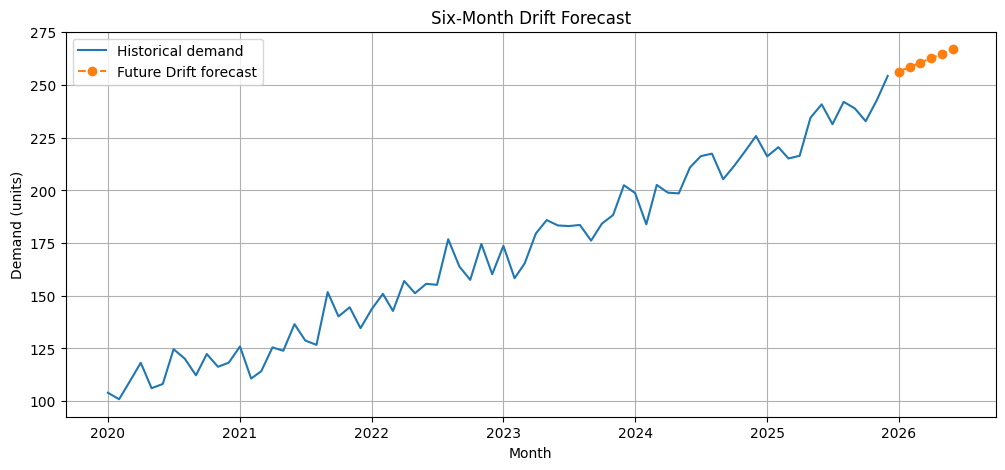

In [15]:
plt.figure()
plt.plot(ts.index, ts, label="Historical demand")
plt.plot(future_forecast.index, future_forecast, marker="o",
         linestyle="--", label="Future Drift forecast")
plt.title("Six-Month Drift Forecast")
plt.xlabel("Month")
plt.ylabel("Demand (units)")
plt.legend()
plt.show()

## 13. Important assumptions and practical considerations

1. **Constant average change:** the method assumes the average change from the first to the last training point continues into the forecast horizon.
2. **No explicit seasonality:** recurring weekly, monthly, or yearly patterns are not modeled.
3. **Endpoint sensitivity:** the first and last training values determine the drift. An unusual endpoint can materially change the forecast.
4. **Structural changes:** a promotion, supply disruption, pricing change, or business event can make historical drift unreliable.
5. **Long horizons:** extrapolation uncertainty generally increases as the horizon grows.
6. **Data quality:** check missing periods, duplicate dates, outliers, and consistent time intervals before forecasting.
7. **Non-negative demand:** the mathematical forecast can become negative for a sufficiently strong downward drift. If demand cannot be negative, apply a business-approved constraint and document it rather than silently changing the model.

## 14. Advantages and limitations

### Advantages
- Simple, transparent, and quick to implement.
- Captures a linear direction in the data.
- Requires no iterative optimization or complex parameter fitting.
- Useful as a benchmark for trend-oriented series.

### Limitations
- Assumes a constant average change.
- Does not model seasonality or nonlinear trends.
- Can be sensitive to the first and last observations.
- Can extrapolate unrealistic values over long horizons.
- May perform poorly when the series is volatile or has structural breaks.

## 15. Common mistakes to avoid

- Using the test set to calculate the drift.
- Dividing by the number of observations instead of the number of intervals (`n - 1`).
- Confusing Drift with Naive: Drift adds a projected change; Naive repeats the last value.
- Assuming the trend will continue indefinitely.
- Ignoring seasonality, outliers, missing dates, or structural changes.
- Comparing models using different train/test periods.

## 16. Practice exercises

Try these exercises after running the notebook:

1. Change the train/test split from 60/12 to 54/18. Does the estimated drift change?
2. Generate a series with a downward trend. Does the Drift method forecast a decline?
3. Add strong seasonality to the synthetic data. How does Drift perform compared with Seasonal Naive?
4. Add an unusually high value at the end of the training data. How much does the drift change?
5. Compare the Drift, Naive, and Average methods on a series with no trend.
6. Forecast 3, 6, and 12 steps ahead. How does the forecast path change?

## 17. Key takeaways

- Drift is a trend-adjusted extension of the Naive forecasting method.
- It estimates average change per time interval using the first and last training observations.
- It projects that change linearly into future periods.
- It is useful as a simple benchmark when a series has a reasonably consistent trend.
- Always evaluate it on a chronological holdout and compare it with other baselines.

## 18. References

- [Forecasting: Principles and Practice – Simple methods](https://otexts.com/fpp3/simple-methods.html)
- [Forecasting: Principles and Practice – Forecast accuracy](https://otexts.com/fpp3/accuracy.html)
- [Pandas documentation](https://pandas.pydata.org/docs/)
- [NumPy documentation](https://numpy.org/doc/)
- [Scikit-learn metrics](https://scikit-learn.org/stable/modules/model_evaluation.html)

---

**Happy Learning! 🚀**